# EDA 06 — South German Credit (bản hiệu chỉnh, Grömping 2019)

Nguồn: UCI “South German Credit” — bản sửa lỗi của German Credit (Statlog) do Grömping (2019) công bố,
với bảng mã (`codetable.txt`) đã được hiệu chỉnh. Nhãn gốc `credit_risk` (0 = bad, 1 = good) → `target = 1 - credit_risk`.
Mọi biến được lưu dạng mã số nguyên.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.visualization import eda

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
INTERIM = ROOT / "data" / "interim"

## 1. Nạp dữ liệu

In [2]:
NAME = "south_german_credit"
df = pd.read_csv(INTERIM / "south_german_credit.csv")
df.shape

(1000, 21)

## 2. Tổng quan

In [3]:
ov = eda.overview(df)
display(ov.to_frame("value"))
display(df.head())

,value
rows,1000.0
features,20.0
numeric_features,20.0
categorical_features,0.0
duplicate_rows,0.0
cells_missing_pct,0.0
features_with_missing,0.0


,status,duration,credit_history,purpose,amount,savings,employment_duration,installment_rate,personal_status_sex,other_debtors,present_residence,property,age,other_installment_plans,housing,number_credits,job,people_liable,telephone,foreign_worker,target
0,1,18,4,2,1049,1,2,4,2,1,4,2,21,3,1,1,3,2,1,2,0
1,1,9,4,0,2799,1,3,2,3,1,2,1,36,3,1,2,3,1,1,2,0
2,2,12,2,9,841,2,4,2,2,1,4,1,23,3,1,1,2,2,1,2,0
3,1,12,4,0,2122,1,3,3,3,1,2,1,39,3,1,2,2,1,1,1,0
4,1,12,4,0,2171,1,3,4,3,1,4,2,38,1,2,2,2,2,1,1,0


## 3. Nhãn (target: 1 = xấu / vỡ nợ, 0 = tốt)

{'n': 1000, 'n_bad': 300, 'n_good': 700, 'bad_rate_pct': 30.0, 'imbalance_ratio': 2.33}


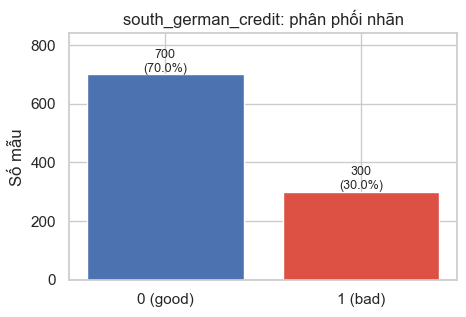

In [4]:
tgt = eda.target_summary(df["target"])
print(tgt)
eda.plot_target(df["target"], NAME)

## 4. Giá trị thiếu

Bảng thứ hai so sánh tỉ lệ nợ xấu khi cột bị thiếu và khi có giá trị: chênh lệch lớn nghĩa là *bản thân việc thiếu* đã mang thông tin về nhãn.

In [5]:
miss = eda.missing_table(df)
display(miss if len(miss) else "Không có giá trị thiếu (NaN).")
mvt = eda.missing_vs_target(df)
display(mvt if len(mvt) else "Không có cột nào đủ lượng thiếu để so sánh bad rate.")

'Không có giá trị thiếu (NaN).'

'Không có cột nào đủ lượng thiếu để so sánh bad rate.'

## 5. Hồ sơ các biến số

`skew`/`kurtosis`: độ lệch và độ nhọn; `outlier_iqr_pct`: % điểm nằm ngoài 1.5×IQR; `zero_pct`: % giá trị 0; `auc`: AUC đơn biến (max(AUC, 1−AUC)) — thước đo nhanh sức phân biệt của từng biến.

In [6]:
prof = eda.numeric_profile(df)
cols_show = ["n_unique", "min", "median", "max", "skew", "kurtosis", "outlier_iqr_pct", "zero_pct", "auc"]
display(prof.sort_values("auc", ascending=False)[cols_show])
print("Số cột số có |skew| > 2:", int((prof["skew"].abs() > 2).sum()), "/", len(prof))

,n_unique,min,median,max,skew,kurtosis,outlier_iqr_pct,zero_pct,auc
feature,,,,,,,,,
status,4,1,2.0,4,0.007,-1.661,0.0,0.0,0.708
duration,33,4,18.0,72,1.093,0.909,7.0,0.0,0.629
credit_history,5,0,2.0,4,-0.012,-0.582,0.0,4.0,0.627
savings,5,1,1.0,5,1.015,-0.683,0.0,0.0,0.597
property,4,1,2.0,4,0.046,-1.238,0.0,0.0,0.585
employment_duration,5,1,3.0,5,-0.117,-0.936,0.0,0.0,0.573
age,53,19,33.0,75,1.023,0.611,2.3,0.0,0.571
amount,923,250,2319.5,18424,1.947,4.265,7.2,0.0,0.555
personal_status_sex,4,1,3.0,4,-0.305,-0.009,0.0,0.0,0.551


Số cột số có |skew| > 2: 1 / 17


## 6. Phân phối theo nhãn

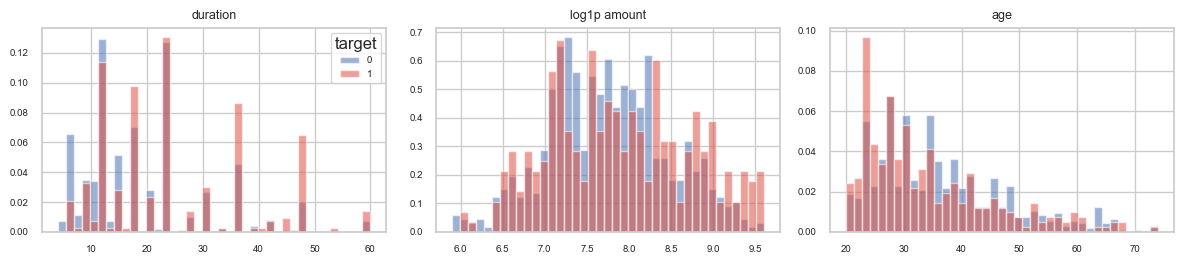

In [7]:
eda.plot_numeric_by_target(df, ["duration", "amount", "age"], NAME, ncols=3, log=["amount"])

## 7. Biến phân loại: tỉ lệ nợ xấu theo nhóm

Đường nét đứt = bad rate chung.

n  bad_rate  share_pct
feature             level                          
status              1      274     49.27       27.4
                    2      269     39.03       26.9
                    3       63     22.22        6.3
                    4      394     11.68       39.4
credit_history      0       40     62.50        4.0
                    1       49     57.14        4.9
                    2      530     31.89       53.0
                    3       88     31.82        8.8
                    4      293     17.06       29.3
savings             1      603     35.99       60.3
                    2      103     33.01       10.3
                    3       63     17.46        6.3
                    4       48     12.50        4.8
                    5      183     17.49       18.3
purpose             0      234     38.03       23.4
                    1      103     16.50       10.3
                    2      181     32.04       18.1
                    3      280     22.14       28.0
                    4       12     33.33        1.2
                    5       22     36.36        2.2
                    6       50     44.00        5.0
                    8        9     11.11        0.9
                    9       97     35.05        9.7
                    10      12     41.67        1.2
employment_duration 1       62     37.10        6.2
                    2      172     40.70       17.2
                    3      339     30.68       33.9
                    4      174     22.41       17.4
                    5      253     25.30       25.3
property            1      282     21.28       28.2
                    2      232     30.60       23.2
                    3      332     30.72       33.2
                    4      154     43.51       15.4
housing             1      179     39.11       17.9
                    2      714     26.05       71.4
                    3      107     41.12       10.7
personal_status_sex 1       50     40.00        5.0
                    2      310     35.16       31.0
                    3      548     26.64       54.8
                    4       92     27.17        9.2
foreign_worker      1       37     10.81        3.7
                    2      963     30.74       96.3

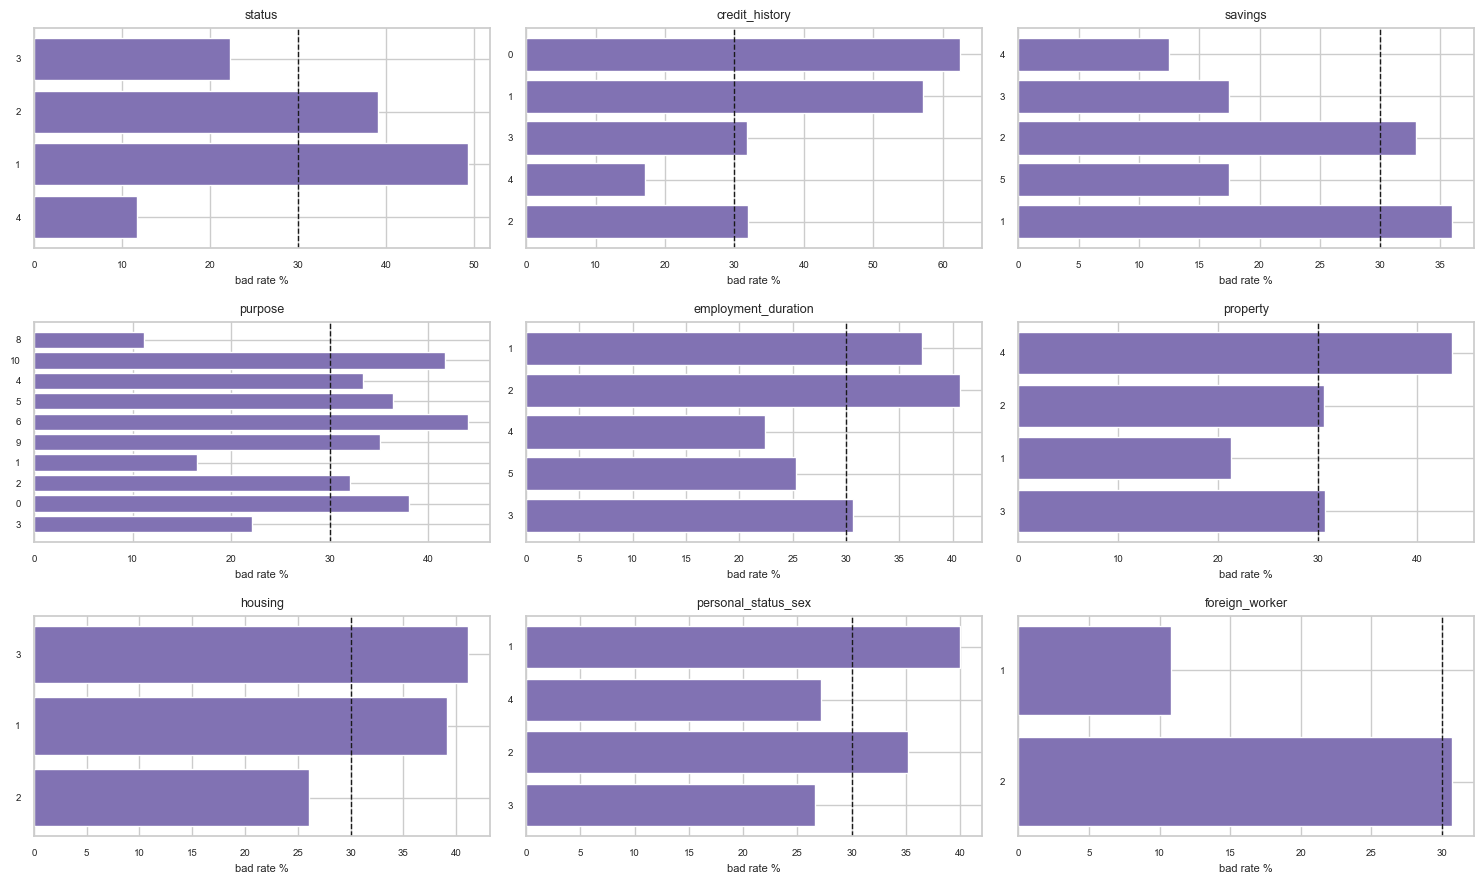

In [8]:
cats = ["status", "credit_history", "savings", "purpose", "employment_duration",
        "property", "housing", "personal_status_sex", "foreign_worker"]
display(eda.categorical_bad_rate(df, cats))
eda.plot_categorical_bad_rate(df, cats, NAME)

## 8. Tương quan

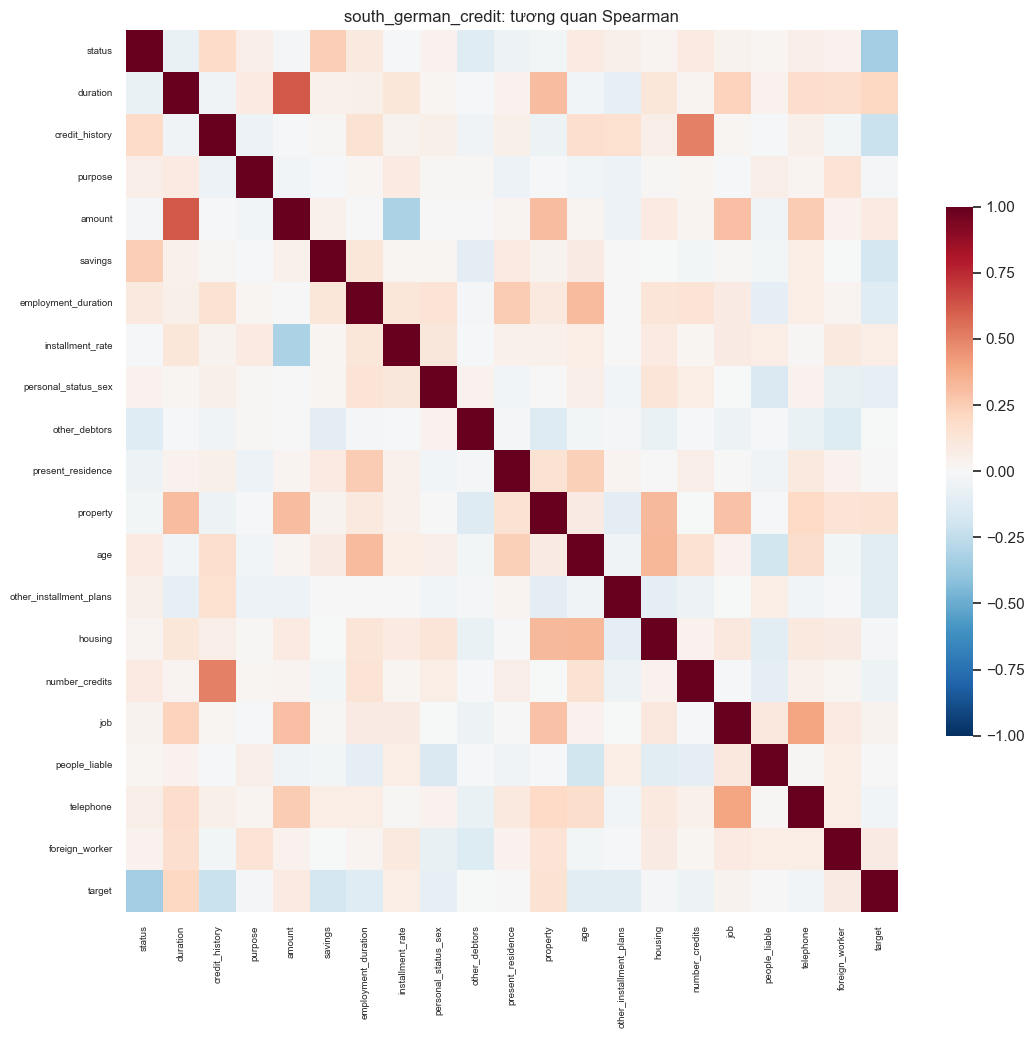

,a,b,spearman


In [9]:
corr = eda.correlation_heatmap(df, NAME)
display(eda.high_corr_pairs(corr, thr=0.9).head(20))

## 9. Kiểm tra riêng cho bộ dữ liệu

### So sánh với bản Statlog

In [10]:
ge = pd.read_csv(INTERIM / "german_credit.csv")
cmp = pd.DataFrame({
    "statlog": [len(ge), ge.target.mean(), ge.credit_amount.sum(), ge.duration.mean(), ge.age.mean()],
    "south_german": [len(df), df.target.mean(), df.amount.sum(), df.duration.mean(), df.age.mean()],
}, index=["rows", "bad_rate", "sum_amount", "mean_duration", "mean_age"])
display(cmp)
print("Hai bộ có cùng thống kê biên nhưng thứ tự dòng khác nhau.")
display(pd.concat({
    "statlog": ge.groupby("credit_history")["target"].agg(["size", "mean"]).sort_values("size"),
    "south_german (mã 0–4)": df.groupby("credit_history")["target"].agg(["size", "mean"]).sort_values("size"),
}, axis=1))

,statlog,south_german
rows,1000.000,1000.000
bad_rate,0.300,0.300
sum_amount,3271258.000,3271248.000
mean_duration,20.903,20.903
mean_age,35.546,35.542


Hai bộ có cùng thống kê biên nhưng thứ tự dòng khác nhau.


statlog           south_german (mã 0–4)          
                                  size      mean                  size      mean
credit_history                                                                  
no credits/all paid               40.0  0.625000                   NaN       NaN
all paid                          49.0  0.571429                   NaN       NaN
delayed previously                88.0  0.318182                   NaN       NaN
critical/other existing credit   293.0  0.170648                   NaN       NaN
existing paid                    530.0  0.318868                   NaN       NaN
0                                  NaN       NaN                  40.0  0.625000
1                                  NaN       NaN                  49.0  0.571429
3                                  NaN       NaN                  88.0  0.318182
4                                  NaN       NaN                 293.0  0.170648
2                                  NaN       NaN                 530.0  0.318868

In [11]:
# Trong bảng mã hiệu chỉnh: 0 = trễ hạn trong quá khứ, 1 = critical account, 2 = không vay/đã trả hết,
# 3 = đang trả đúng hạn, 4 = đã trả hết tại ngân hàng này. Với nhãn đúng, bad rate giảm dần theo mã → hợp lý.

## 10. Nhận xét

- **Nhãn:** giống hệt Statlog — **30%** bad, cùng 1.000 người vay (cùng phân phối biên, chỉ khác thứ tự dòng và cách mã hoá).
- **Điểm khác duy nhất đáng kể là ý nghĩa mã hoá:** với bảng mã đã hiệu chỉnh, nhóm “trễ hạn trong quá khứ” có bad rate cao nhất (~62%) và nhóm “đã trả hết tại ngân hàng này” thấp nhất (~17%) — quan hệ giờ **hợp lý về mặt nghiệp vụ**, giải quyết điểm phản trực giác ở bản Statlog. Hiệu năng mô hình không đổi (thông tin như nhau), nhưng **diễn giải** thì đúng hơn.
- Tất cả biến là mã số nguyên; nếu đưa thẳng vào mô hình tuyến tính sẽ ngầm giả định thứ tự → nên one-hot hoặc dùng mô hình cây.
- Nhỏ, không missing, không trùng lặp, ít lệch.

In [12]:
EXTRA = {}
eda.save_summary(NAME, {
    "name": NAME,
    "overview": ov.to_dict(),
    "target": tgt,
    "missing_top": miss["missing_pct"].head(10).to_dict() if len(miss) else {},
    "n_numeric_abs_skew_gt2": int((prof["skew"].abs() > 2).sum()),
    "n_numeric": int(len(prof)),
    "max_abs_skew": float(prof["skew"].abs().max()),
    "top_auc": prof["auc"].sort_values(ascending=False).head(5).to_dict(),
    **EXTRA,
})